# Imports

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import f1_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
import shap
from sklearn.model_selection import RandomizedSearchCV
from sklearn.calibration import CalibratedClassifierCV
from sklearn.calibration import calibration_curve

In [2]:
data = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# EDA and cleaning

In [3]:
data.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
data.duplicated().sum()

np.int64(0)

In [6]:
NA_table = pd.DataFrame({"NA_count": data.isnull().sum(),
                         "NA_Proportion": (data.isnull().sum() / len(data)) * 100})

NA_table.sort_values("NA_count", ascending=False, inplace=True)
NA_table.head(10)

,NA_count,NA_Proportion
customerID,0,0.0
DeviceProtection,0,0.0
TotalCharges,0,0.0
MonthlyCharges,0,0.0
PaymentMethod,0,0.0
PaperlessBilling,0,0.0
Contract,0,0.0
StreamingMovies,0,0.0
StreamingTV,0,0.0
TechSupport,0,0.0


In [7]:
data.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")

In [9]:
data["TotalCharges"].isna().sum()

np.int64(11)

In [10]:
data[data["TotalCharges"].isna()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [11]:
data["TotalCharges"] = data["TotalCharges"].fillna(0)

In [12]:
data["TotalCharges"].isna().sum()

np.int64(0)

Missing values in the feature *TotalCharges* correspond to new customers (tenure = 0). These were imputed with 0, as no charges have been incurred yet.

In [13]:
data.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

In [14]:
data.rename(columns={
    "gender": "Gender",
    "tenure": "Tenure",
}, inplace=True)

## Categorical features

In [15]:
categorical_features = data.select_dtypes(include=["object", "str"]).columns

categorical_features = categorical_features.drop("customerID", errors="ignore")

print("Number of unique values and unique values in each categorical feature:")
for feature in categorical_features:
    print(f"{feature}: {len(data[feature].unique())}, {data[feature].unique()}")

Number of unique values and unique values in each categorical feature:
Gender: 2, <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Partner: 2, <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents: 2, <StringArray>
['No', 'Yes']
Length: 2, dtype: str
PhoneService: 2, <StringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines: 3, <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService: 3, <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity: 3, <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup: 3, <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtection: 3, <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
TechSupport: 3, <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingTV: 3, <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingMovies: 3, <StringArray>
['No', '

In [16]:
data["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [17]:
data["Churn"].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [18]:
data.groupby("Contract")["Churn"].value_counts(normalize=True)

Contract        Churn
Month-to-month  No       0.572903
                Yes      0.427097
One year        No       0.887305
                Yes      0.112695
Two year        No       0.971681
                Yes      0.028319
Name: proportion, dtype: float64

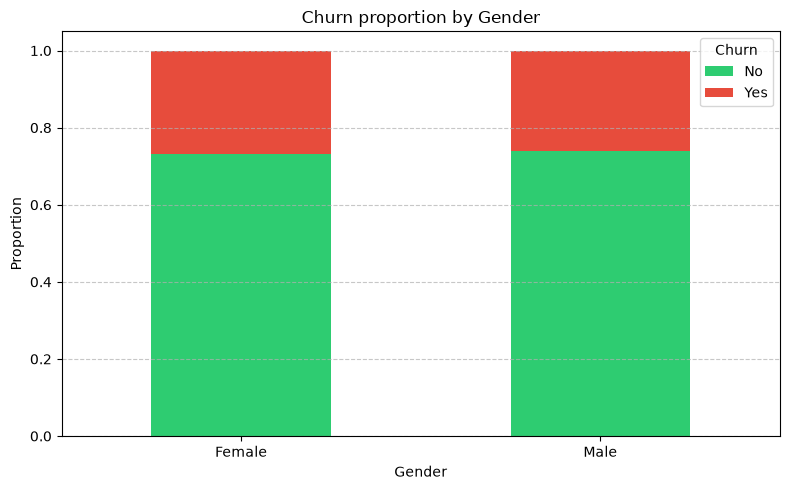

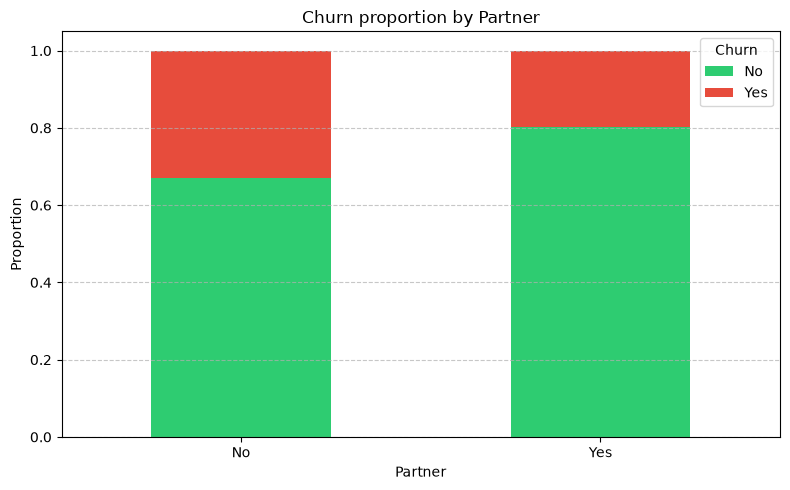

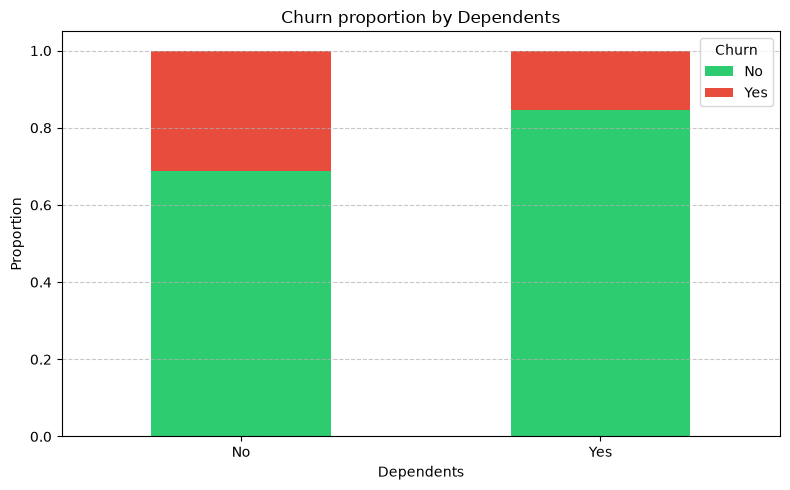

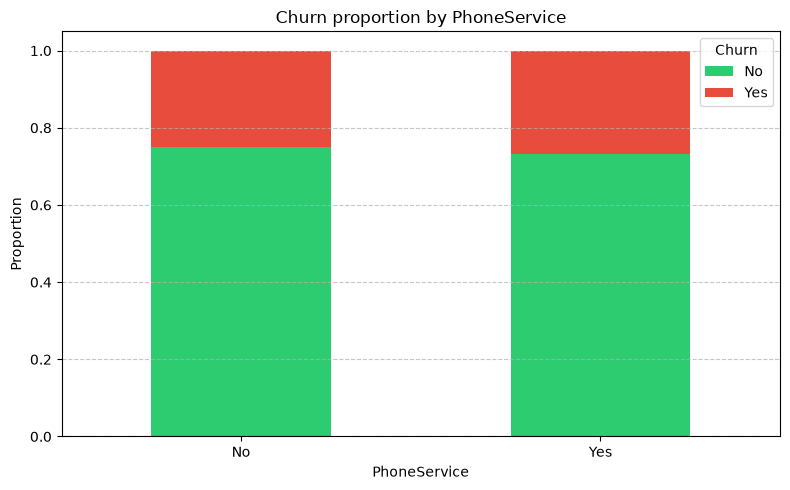

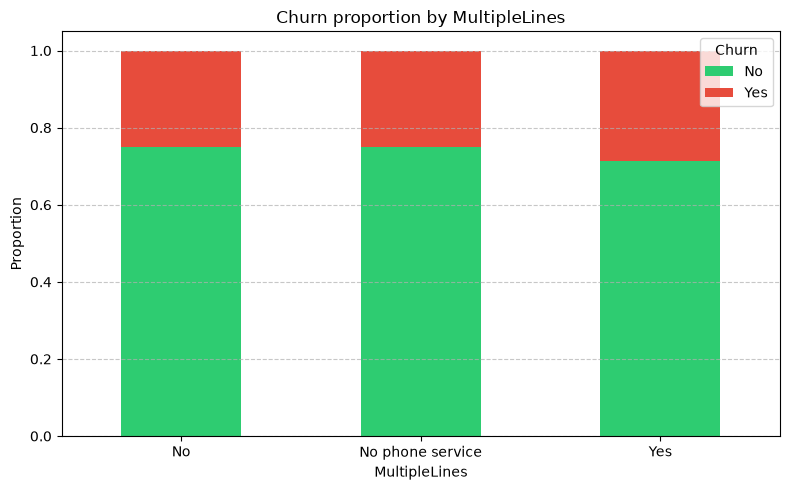

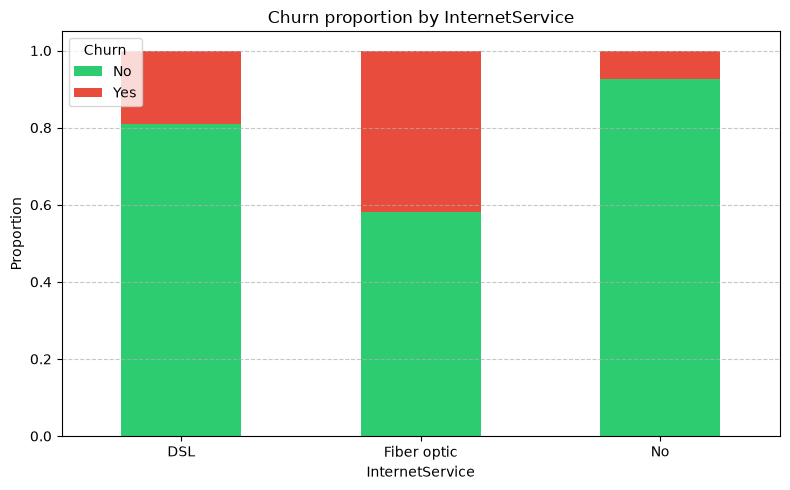

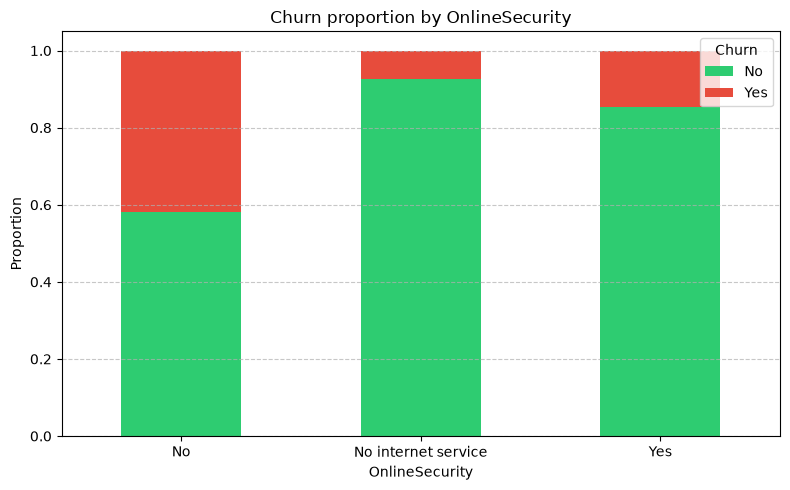

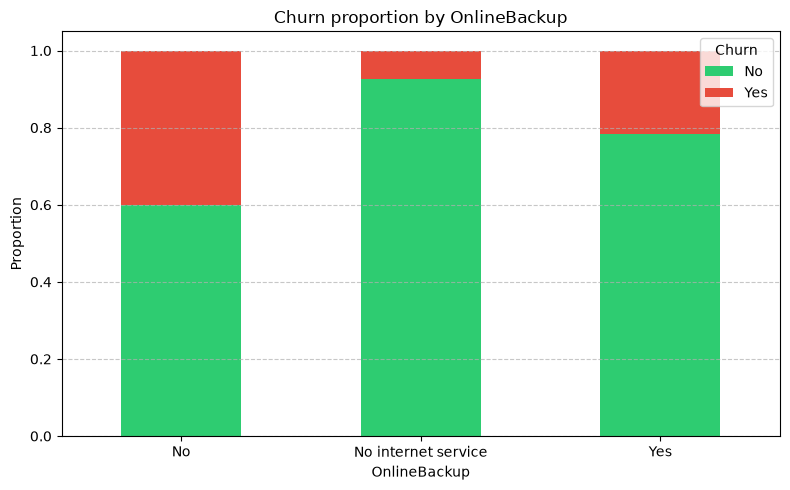

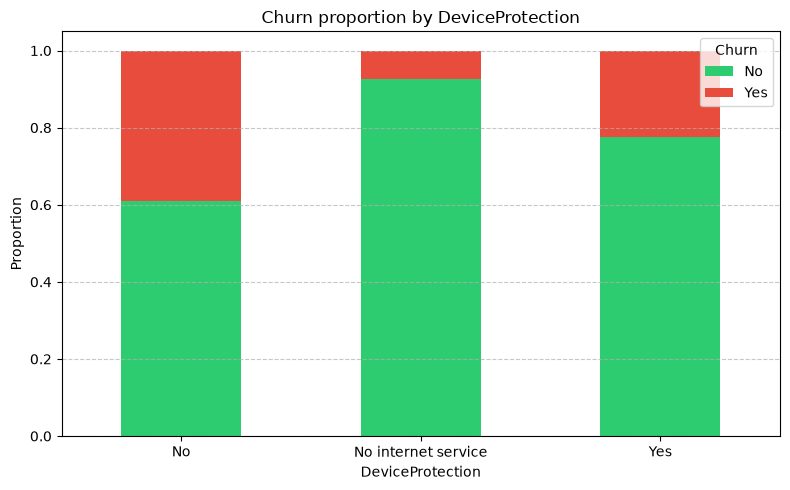

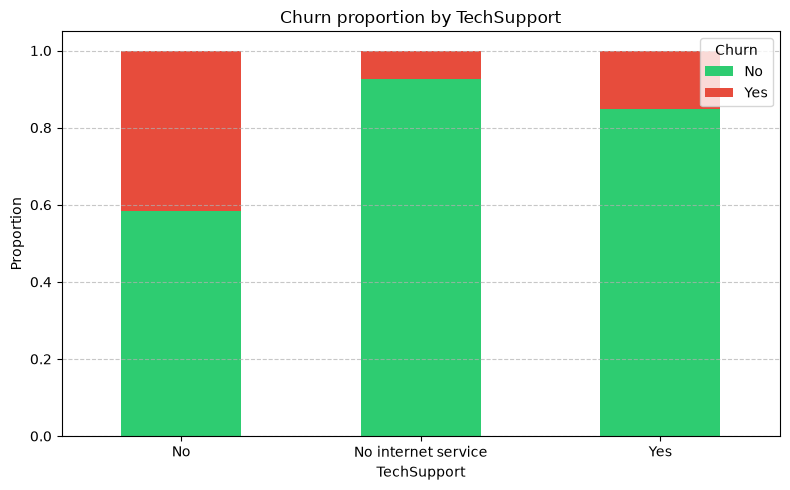

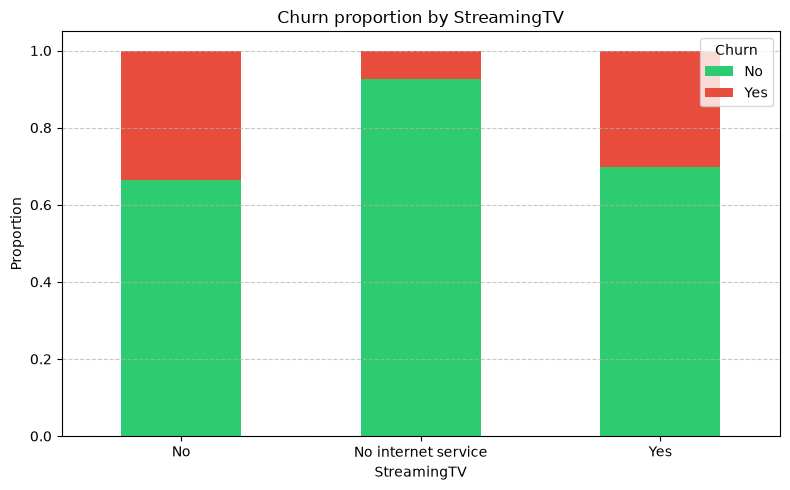

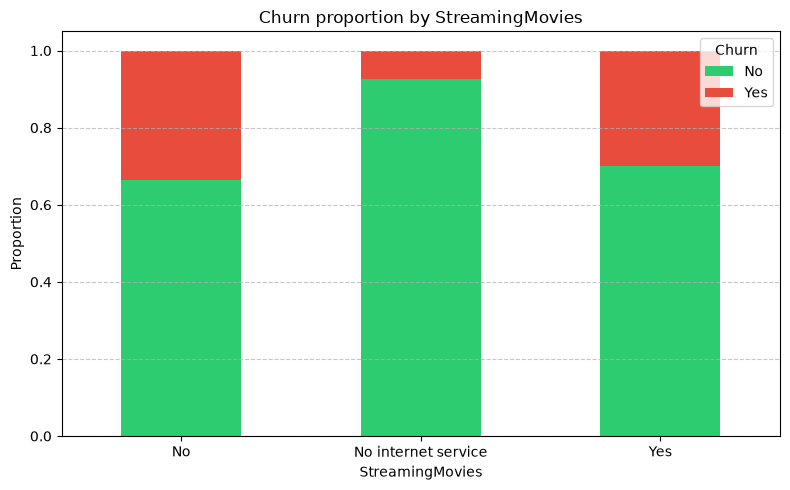

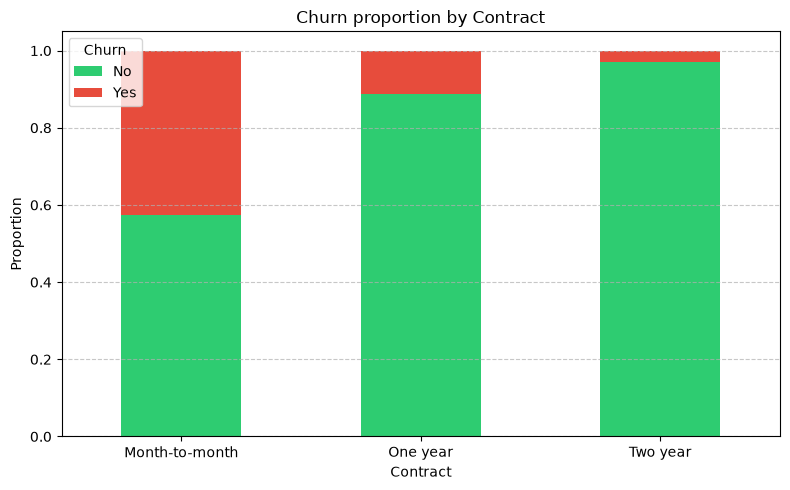

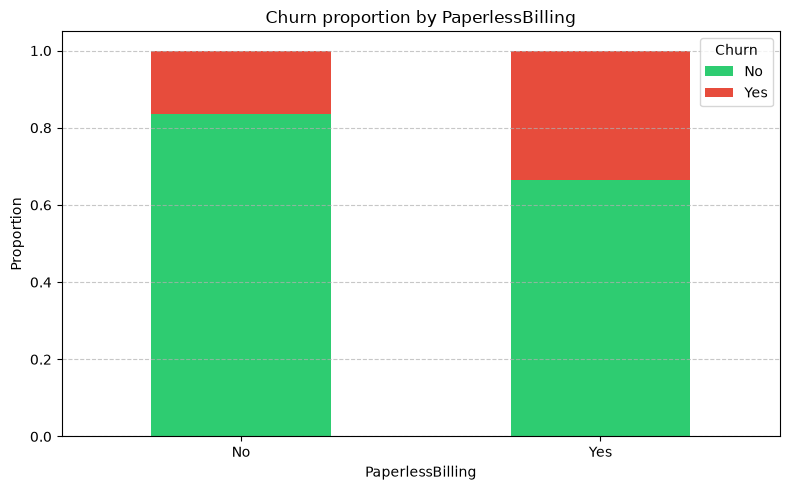

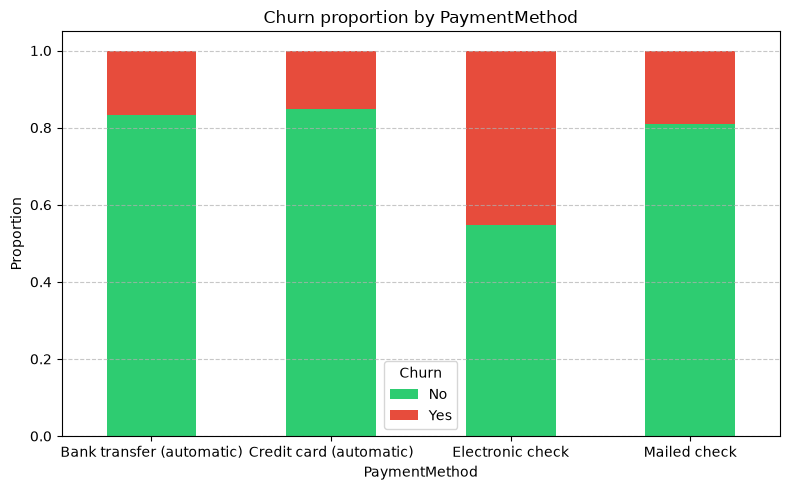

In [19]:
for feature in categorical_features:
    
    if feature == "Churn":
        continue
    
    churn_rate = pd.crosstab(data[feature], data["Churn"], normalize="index")
    
    churn_rate.plot(
        kind="bar",
        stacked=True,
        figsize=(8, 5),
        color=["#2ecc71", "#e74c3c"]
    )
    
    plt.title(f"Churn proportion by {feature}")
    plt.ylabel("Proportion")
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

### Contract

In [20]:
contract_table = pd.crosstab(data["Contract"], data["Churn"])

contract_rate = pd.crosstab(data["Contract"], data["Churn"], normalize="index")

contract_summary = contract_table.join(contract_rate, rsuffix="_rate")

contract_summary.rename(columns={
    "No": "No_count",
    "Yes": "Yes_count",
    "No_rate": "No_rate",
    "Yes_rate": "Churn_rate"
}, inplace=True)

print(contract_summary)

Churn           No_count  Yes_count   No_rate  Churn_rate
Contract                                                 
Month-to-month      2220       1655  0.572903    0.427097
One year            1307        166  0.887305    0.112695
Two year            1647         48  0.971681    0.028319


Churn decreases with the length of the contract.

### Additionnal Services

In [21]:
services = [
    "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport"
]

service_summary = []

for service in services:
    churn_rate = pd.crosstab(data[service], data["Churn"], normalize="index")
    
    service_summary.append({
        "Feature": service,
        "No_service_churn": churn_rate.loc["No", "Yes"],
        "Yes_service_churn": churn_rate.loc["Yes", "Yes"]
    })
    
service_summary = pd.DataFrame(service_summary) ; service_summary

,Feature,No_service_churn,Yes_service_churn
0,OnlineSecurity,0.417667,0.146112
1,OnlineBackup,0.399288,0.215315
2,DeviceProtection,0.391276,0.225021
3,TechSupport,0.416355,0.151663


Churn is always lower with additionnal services, but this is probably a selection bias.

## Numerical features

In [22]:
data.describe()

,SeniorCitizen,Tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [23]:
data["SeniorCitizen"].head()

0    0
1    0
2    0
3    0
4    0
Name: SeniorCitizen, dtype: int64

In [24]:
numerical_features = data.select_dtypes(include="number").columns

numerical_features = numerical_features.drop("SeniorCitizen")

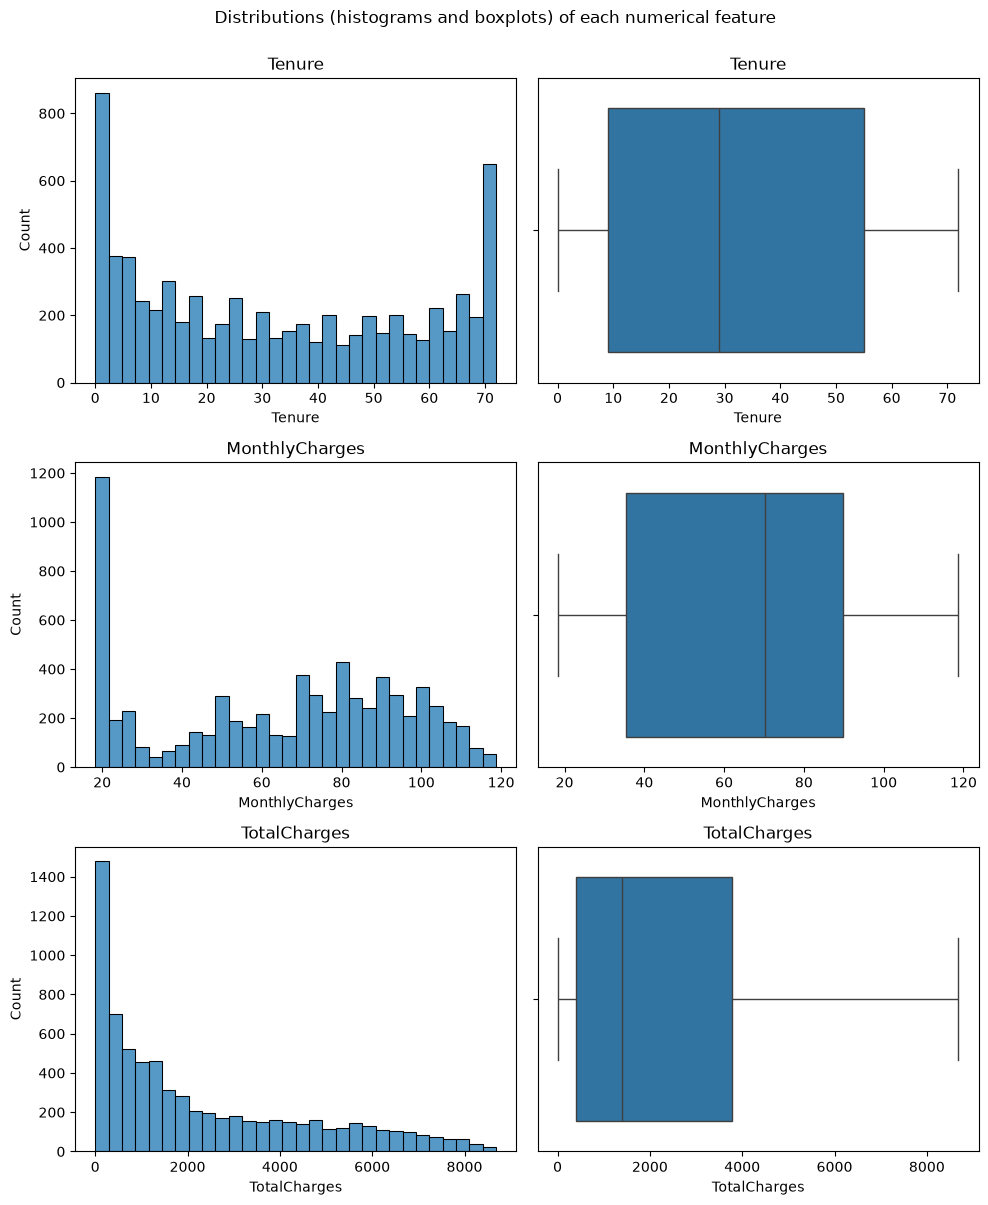

In [25]:
fig, axes = plt.subplots(len(numerical_features),
                        2,
                        figsize=(10, 4 * len(numerical_features)
                        ))

for ax, numerical_feature in zip(axes, numerical_features):
    
    sns.histplot(data[numerical_feature], ax=ax[0], bins=30)
    ax[0].set_title(f"{numerical_feature}")
    
    sns.boxplot(x=data[numerical_feature], ax=ax[1])
    ax[1].set_title(f"{numerical_feature}")
    
plt.suptitle("Distributions (histograms and boxplots) of each numerical feature", y=1)
plt.tight_layout()
plt.show()

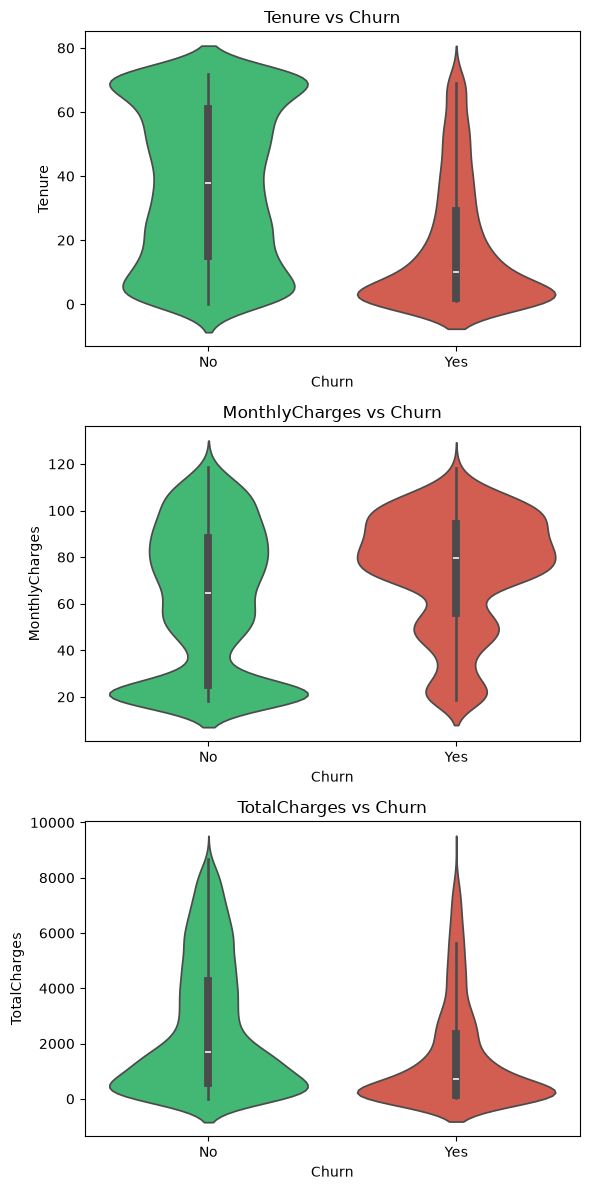

In [26]:
palette = {"Yes": "#e74c3c", "No": "#2ecc71"}

fig, axes = plt.subplots(len(numerical_features),
                         1,
                         figsize=(6, 4 * len(numerical_features)))

for ax, numerical_feature in zip(axes, numerical_features):
    sns.violinplot(data=data, x="Churn", y=numerical_feature, hue="Churn", palette=palette, legend=False, ax=ax)
    ax.set_title(f"{numerical_feature} vs Churn")
    
plt.tight_layout()
plt.show()

## Churn Prediction Modeling

### Data preparation

Let's drop *customerID*:

In [27]:
data = data.drop("customerID", axis=1)

And transform *Churn* into a boolean numerical variable:

In [28]:
data["Churn"] = data["Churn"].map({"Yes": 1, "No": 0})

In [29]:
data["Churn"].head(5)

0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

Let's encode the categorical variables:

In [30]:
data_encoded = pd.get_dummies(data, drop_first=True)

In [31]:
data_encoded.head()

,SeniorCitizen,Tenure,MonthlyCharges,TotalCharges,Churn,Gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False


In [32]:
X = data_encoded.drop("Churn", axis=1)
y = data_encoded["Churn"]

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

### Baseline Logistic Regression

In [34]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

/opt/miniconda3/envs/churn/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [35]:
y_pred = model.predict(X_test)

In [36]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8218594748048261

Confusion matrix:
[[934 102]
 [149 224]]

Classification report:
              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1036
           1       0.69      0.60      0.64       373

    accuracy                           0.82      1409
   macro avg       0.77      0.75      0.76      1409
weighted avg       0.82      0.82      0.82      1409



In [37]:
y.mean()

np.float64(0.2653698707936959)

In [38]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

coefficients = coefficients.sort_values("Coefficient", ascending=False)

In [39]:
coefficients.head(15)

,Feature,Coefficient
10,InternetService_Fiber optic,0.646414
26,PaperlessBilling_Yes,0.335716
28,PaymentMethod_Electronic check,0.326064
8,MultipleLines_No phone service,0.278370
23,StreamingMovies_Yes,0.231441
9,MultipleLines_Yes,0.220602
0,SeniorCitizen,0.160113
21,StreamingTV_Yes,0.127558
5,Partner_Yes,0.056674
2,MonthlyCharges,0.002567


In [40]:
coefficients.tail(15)

,Feature,Coefficient
27,PaymentMethod_Credit card (automatic),-0.087199
12,OnlineSecurity_No internet service,-0.101964
20,StreamingTV_No internet service,-0.101964
22,StreamingMovies_No internet service,-0.101964
11,InternetService_No,-0.101964
18,TechSupport_No internet service,-0.101964
16,DeviceProtection_No internet service,-0.101964
14,OnlineBackup_No internet service,-0.101964
6,Dependents_Yes,-0.157222
15,OnlineBackup_Yes,-0.211078


In [41]:
y_proba = model.predict_proba(X_test)[:,1]

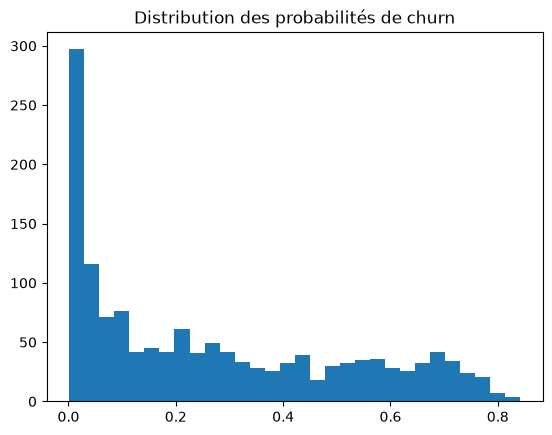

In [42]:
plt.hist(y_proba, bins=30)
plt.title("Distribution des probabilités de churn")
plt.show()

In [43]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [44]:
model.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [45]:
y_pred_scaled = model.predict(X_test_scaled)

In [46]:
print("Accuracy:", accuracy_score(y_test, y_pred_scaled))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_scaled))
print("\nClassification report:")
print(classification_report(y_test, y_pred_scaled))

Accuracy: 0.8204400283889283

Confusion matrix:
[[934 102]
 [151 222]]

Classification report:
              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1036
           1       0.69      0.60      0.64       373

    accuracy                           0.82      1409
   macro avg       0.77      0.75      0.76      1409
weighted avg       0.81      0.82      0.82      1409



In [47]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

coefficients = coefficients.sort_values("Coefficient", ascending=False)

In [48]:
coefficients

,Feature,Coefficient
3,TotalCharges,0.649427
10,InternetService_Fiber optic,0.619853
23,StreamingMovies_Yes,0.228714
21,StreamingTV_Yes,0.179380
9,MultipleLines_Yes,0.168199
26,PaperlessBilling_Yes,0.163829
28,PaymentMethod_Electronic check,0.150618
0,SeniorCitizen,0.058854
8,MultipleLines_No phone service,0.035633
17,DeviceProtection_Yes,0.027786


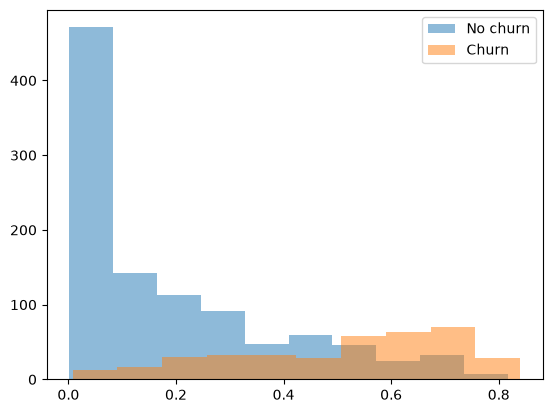

In [49]:
y_proba_scaled = model.predict_proba(X_test_scaled)[:,1]

plt.hist(y_proba_scaled[y_test==0], alpha=0.5, label="No churn")
plt.hist(y_proba_scaled[y_test==1], alpha=0.5, label="Churn")
plt.legend()
plt.show()

After scaling numerical variables, logistic regression achieved an accuracy of 82% and a churn recall of 60%, indicating a solid but imperfect baseline model. The strongest protective factors agains churn are customer tenure and long-term contracts, while fiber optic service, paperless billing, and electronic check payment are associated with higher churn risk.

Probability distributions show that the model separates churn and non-churn, though with substancial overlap, suggesting that churn remains only partially predictable from the available features.

As false negatives are more costly than false positives (missing real churners is more costly than contacting loyal customers), the primary objective is to improve recall, even at the cost of an increase in false positives.

The threshold for churn detection could thus be lowered to 0.3:

In [50]:
threshold = 0.3
y_pred_03 = (y_proba_scaled > threshold).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred_03))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_03))
print("\nClassification report:")
print(classification_report(y_test, y_pred_03))

Accuracy: 0.7764371894960965

Confusion matrix:
[[795 241]
 [ 74 299]]

Classification report:
              precision    recall  f1-score   support

           0       0.91      0.77      0.83      1036
           1       0.55      0.80      0.65       373

    accuracy                           0.78      1409
   macro avg       0.73      0.78      0.74      1409
weighted avg       0.82      0.78      0.79      1409



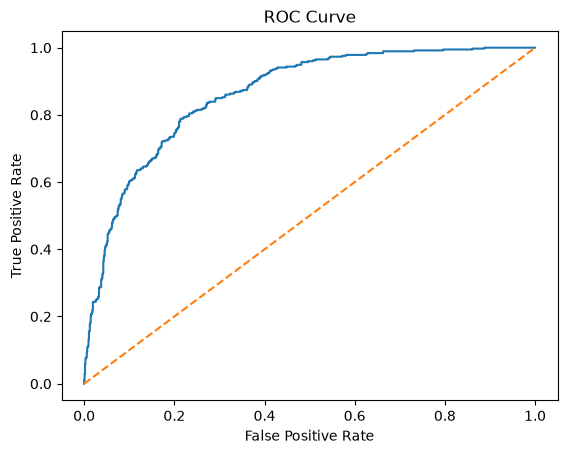

ROC AUC: 0.8621256741229931


In [51]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba_scaled)

plt.plot(fpr, tpr)
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

print("ROC AUC:", roc_auc_score(y_test, y_proba_scaled))

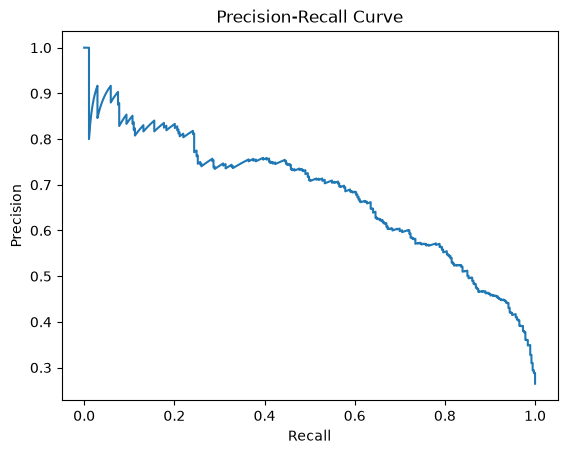

In [52]:
precision, recall, thresholds = precision_recall_curve(y_test, y_proba_scaled)

plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.show()

In [53]:
thresholds = np.arange(0.1, 0.9, 0.01)
f1_scores = []

for t in thresholds:
    y_pred_t = (y_proba_scaled > t).astype(int)
    f1_scores.append(f1_score(y_test, y_pred_t))

best_threshold = thresholds[np.argmax(f1_scores)]

print("Best threshold:", best_threshold)
print("Best F1 score:", max(f1_scores))

Best threshold: 0.3199999999999999
Best F1 score: 0.6621621621621622


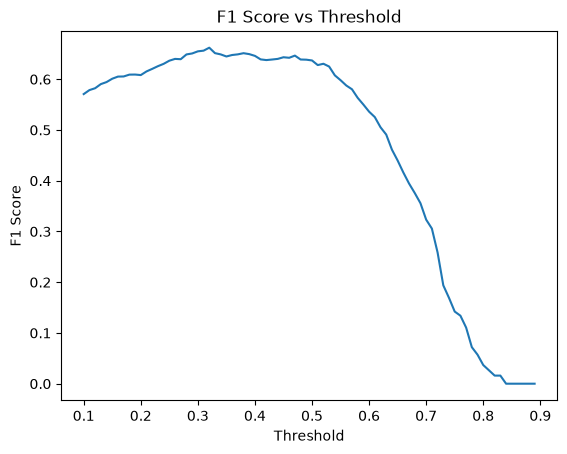

In [54]:
plt.plot(thresholds, f1_scores)
plt.xlabel("Threshold")
plt.ylabel("F1 Score")
plt.title("F1 Score vs Threshold")
plt.show()

In [55]:
threshold = max(f1_scores)

y_pred_optimal = (y_proba_scaled > threshold).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred_optimal))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_optimal))
print("\nClassification report:")
print(classification_report(y_test, y_pred_optimal))

Accuracy: 0.7856635911994322

Confusion matrix:
[[1000   36]
 [ 266  107]]

Classification report:
              precision    recall  f1-score   support

           0       0.79      0.97      0.87      1036
           1       0.75      0.29      0.41       373

    accuracy                           0.79      1409
   macro avg       0.77      0.63      0.64      1409
weighted avg       0.78      0.79      0.75      1409



### More feature engineering

L'effet de Tenure n'est pas purement linéaire. Or, la régression logistique peut mieux capter un pattern si on lui fournit des segments : binning.

In [56]:
data_exp = data.copy()

On peut créer une feature RecentCustomer :

In [57]:
data_exp["RecentCustomer"] = (data_exp["Tenure"] <= 12).astype(int)

data_exp["RecentCustomer"].head()

0    1
1    0
2    1
3    0
4    1
Name: RecentCustomer, dtype: int64

A tester pour MonthlyCharges :

In [58]:
data_exp["HighMonthlyCharges"] = (data_exp["MonthlyCharges"] >= 70).astype(int)

data_exp["HighMonthlyCharges"].head()

0    0
1    0
2    0
3    0
4    1
Name: HighMonthlyCharges, dtype: int64

On peut également attribuer un score par observation en agrégeant des features comme les services :

In [59]:
service_cols = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies"
]

data_exp["NumServicesYes"] = sum((data_exp[col] == "Yes").astype(int) for col in service_cols)

data_exp["NumServicesYes"].head(15)

0     1
1     2
2     2
3     3
4     0
5     3
6     2
7     1
8     4
9     2
10    1
11    0
12    3
13    4
14    5
Name: NumServicesYes, dtype: int64

Il pourrait être judicieux de prendre en compte les potentielles interactions entre features puisque celles-ci ne sont pas captées naturellement par la régression logistique.

In [60]:
data_exp["ElectronicCheck_Paperless"] = (
    (data_exp["PaymentMethod"] == "Electronic check") &
    (data_exp["PaperlessBilling"] == "Yes")
).astype(int) 

data_exp["ElectronicCheck_Paperless"].head()

0    1
1    0
2    0
3    0
4    1
Name: ElectronicCheck_Paperless, dtype: int64

In [61]:
data_exp_encoded = pd.get_dummies(data_exp, drop_first=True)

X_exp = data_exp_encoded.drop("Churn", axis=1)
y_exp = data_exp_encoded["Churn"]

X_exp_train, X_exp_test, y_exp_train, y_exp_test = train_test_split(
    X_exp, y_exp,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()
X_exp_train_scaled = scaler.fit_transform(X_exp_train)
X_exp_test_scaled = scaler.transform(X_exp_test)

model.fit(X_exp_train_scaled, y_exp_train)
y_exp_pred_scaled = model.predict(X_exp_test_scaled)

In [62]:
print("Accuracy:", accuracy_score(y_exp_test, y_exp_pred_scaled))
print("\nConfusion matrix:")
print(confusion_matrix(y_exp_test, y_exp_pred_scaled))
print("\nClassification report:")
print(classification_report(y_exp_test, y_exp_pred_scaled))

Accuracy: 0.8112136266855926

Confusion matrix:
[[934 102]
 [164 209]]

Classification report:
              precision    recall  f1-score   support

           0       0.85      0.90      0.88      1036
           1       0.67      0.56      0.61       373

    accuracy                           0.81      1409
   macro avg       0.76      0.73      0.74      1409
weighted avg       0.80      0.81      0.81      1409



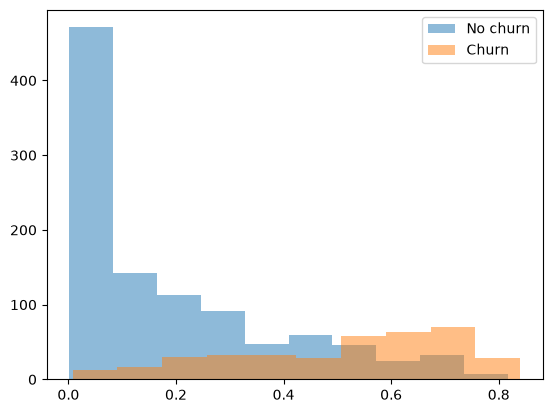

In [63]:
y_exp_proba_scaled = model.predict_proba(X_exp_test_scaled)[:,1]

plt.hist(y_proba_scaled[y_test==0], alpha=0.5, label="No churn")
plt.hist(y_proba_scaled[y_test==1], alpha=0.5, label="Churn")
plt.legend()
plt.show()

In [64]:
threshold = 0.3
y_exp_pred_03 = (y_exp_proba_scaled > threshold).astype(int)

print("Accuracy:", accuracy_score(y_exp_test, y_exp_pred_03))
print("\nConfusion matrix:")
print(confusion_matrix(y_exp_test, y_exp_pred_03))
print("\nClassification report:")
print(classification_report(y_exp_test, y_exp_pred_03))

Accuracy: 0.7700496806245565

Confusion matrix:
[[790 246]
 [ 78 295]]

Classification report:
              precision    recall  f1-score   support

           0       0.91      0.76      0.83      1036
           1       0.55      0.79      0.65       373

    accuracy                           0.77      1409
   macro avg       0.73      0.78      0.74      1409
weighted avg       0.81      0.77      0.78      1409



On peut directement constater que plus de features ne veut pas dire meilleur modèle. Ici, il y a probablement trop de bruit.

Notammenent probablement dû à la multicolinéarité entre Tenure et RecentCustomer.

### Random Forest

At this point, it seems that customer churn depends on tenure, contract type, services and combinations of those features. Logistic regression is not best suited for cases with interactions, whereas Random Forest capt this naturally.

In [65]:
rf = RandomForestClassifier(
    n_estimators = 100,
    max_depth = None,
    random_state = 42,
    n_jobs =-1
)

In [66]:
rf.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [67]:
y_pred = rf.predict(X_test)
y_proba = rf.predict_proba(X_test)[:, 1]

In [68]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.7863733144073811

Confusion matrix:
[[945  91]
 [210 163]]

Classification report:
              precision    recall  f1-score   support

           0       0.82      0.91      0.86      1036
           1       0.64      0.44      0.52       373

    accuracy                           0.79      1409
   macro avg       0.73      0.67      0.69      1409
weighted avg       0.77      0.79      0.77      1409



In [69]:
importances = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False)

importances.head(10)

,Feature,Importance
3,TotalCharges,0.192397
2,MonthlyCharges,0.172436
1,Tenure,0.172147
10,InternetService_Fiber optic,0.036995
28,PaymentMethod_Electronic check,0.035360
25,Contract_Two year,0.029738
13,OnlineSecurity_Yes,0.029331
4,Gender_Male,0.026950
26,PaperlessBilling_Yes,0.025991
5,Partner_Yes,0.023934


In [70]:
y_pred_03 = (y_proba > 0.3).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred_03))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_03))
print("\nClassification report:")
print(classification_report(y_test, y_pred_03))

Accuracy: 0.7686302342086586

Confusion matrix:
[[804 232]
 [ 94 279]]

Classification report:
              precision    recall  f1-score   support

           0       0.90      0.78      0.83      1036
           1       0.55      0.75      0.63       373

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409



In [71]:
perm = permutation_importance(
    rf, X_test, y_test,
    n_repeats = 10,
    random_state = 42,
    n_jobs = -1
)

importances_perm = pd.DataFrame({
    "Feature": X.columns,
    "Importance": perm.importances_mean
}).sort_values("Importance", ascending=False)

importances_perm.head(10)

,Feature,Importance
10,InternetService_Fiber optic,6.458481e-03
1,Tenure,5.464869e-03
25,Contract_Two year,1.987225e-03
19,TechSupport_Yes,1.774308e-03
24,Contract_One year,1.490419e-03
26,PaperlessBilling_Yes,1.110223e-17
15,OnlineBackup_Yes,-7.806955e-04
14,OnlineBackup_No internet service,-1.419446e-03
27,PaymentMethod_Credit card (automatic),-1.632363e-03
22,StreamingMovies_No internet service,-1.703336e-03


Le fait que la RF ne soit pas aussi performante indique des relations relativement simples, peu d'interactions complexes et une relation réelle de type paramétrique avec une structure quasi log-linéaire.

La faible importance de Contract_Two et Contract_One vient de leur corrélation entre eux et avec Tenure. L'information est redondante et l'importance est donc diluée.

### XGBoost

Plusieurs des propriétés du boosting en font une bonne méthode pour les données tabulaires et ce cas précis :  
    1. Capte les non-linéarités (churn élevé si tenure très faible puis beaucoup plus faible ensuite  
    2. Capte les interactions entre plusieurs features  
    3. En optimisant les résidus, il prend en compte les zones difficiles du dataset
    
En revanche, il est :   
    1. Sensible au tuning (plus que RF)  
    2. Prompt à l'overfitting (p.e. trop d'arbres trop profonds et avec un learning rate trop important)  
    3. Moins interprétable que les régressions

In [72]:
xgb = XGBClassifier(
    n_estimators = 100,
    max_depth = 3,
    learning_rate = 0.1,
    subsample = 0.8,
    colsample_bytree = 0.8,
    random_state = 42,
    eval_metric = "logloss"
)

In [73]:
xgb.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [74]:
y_pred = xgb.predict(X_test)
y_proba = xgb.predict_proba(X_test)[:, 1]

In [75]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.8112136266855926
[[938  98]
 [168 205]]
              precision    recall  f1-score   support

           0       0.85      0.91      0.88      1036
           1       0.68      0.55      0.61       373

    accuracy                           0.81      1409
   macro avg       0.76      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [76]:
threshold = 0.3
y_pred_03 = (y_proba > threshold).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred_03))
print(confusion_matrix(y_test, y_pred_03))
print(classification_report(y_test, y_pred_03))

Accuracy: 0.7743080198722498
[[792 244]
 [ 74 299]]
              precision    recall  f1-score   support

           0       0.91      0.76      0.83      1036
           1       0.55      0.80      0.65       373

    accuracy                           0.77      1409
   macro avg       0.73      0.78      0.74      1409
weighted avg       0.82      0.77      0.79      1409



#### Hyperparameter tuning (cross validation)

In [77]:
param_dist = {
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.05, 0.1],
    "n_estimators": [100, 200, 300],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
}

search = RandomizedSearchCV(
    xgb,
    param_distributions = param_dist,
    n_iter = 20,
    scoring = "roc_auc",
    cv = 5,
    n_jobs = 1,
    random_state = 42,
    )

search.fit(X_train, y_train)

print(search.best_params_)

{'subsample': 0.6, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.8}


In [78]:
best_xgb = search.best_estimator_

#### Calibration

In [79]:
calibrated_xgb = CalibratedClassifierCV(
    best_xgb,
    method="sigmoid",
    cv=5)

calibrated_xgb.fit(X_train, y_train)

y_proba_cal = calibrated_xgb.predict_proba(X_test)[:, 1]

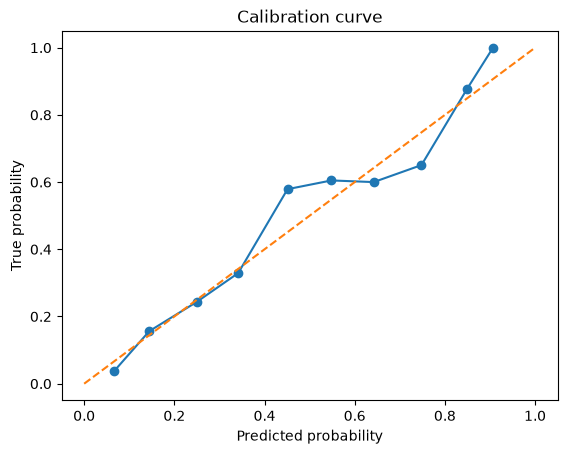

In [80]:
prob_true, prob_pred = calibration_curve(y_test, y_proba_cal, n_bins=10)

plt.plot(prob_pred, prob_true, marker='o')
plt.plot([0,1],[0,1],'--')
plt.xlabel("Predicted probability")
plt.ylabel("True probability")
plt.title("Calibration curve")
plt.show()

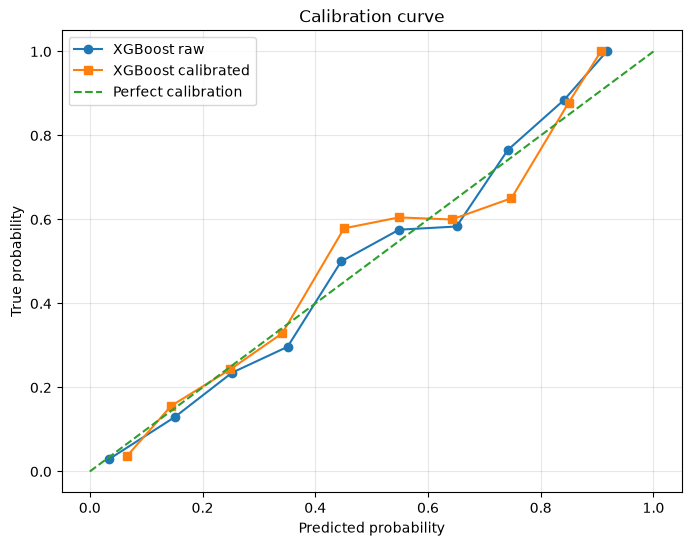

In [81]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true_raw, prob_pred_raw = calibration_curve(y_test, y_proba, n_bins=10)
prob_true_cal, prob_pred_cal = calibration_curve(y_test, y_proba_cal, n_bins=10)

plt.figure(figsize=(8, 6))
plt.plot(prob_pred_raw, prob_true_raw, marker='o', label="XGBoost raw")
plt.plot(prob_pred_cal, prob_true_cal, marker='s', label="XGBoost calibrated")
plt.plot([0, 1], [0, 1], '--', label="Perfect calibration")

plt.xlabel("Predicted probability")
plt.ylabel("True probability")
plt.title("Calibration curve")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#### Threshold tuning

In [82]:
thresholds = np.arange(0.2, 0.96, 0.01)

results = []

for t in thresholds:
    y_pred_t = (y_proba_cal >= t).astype(int)
    
    results.append({
        "threshold": t,
        "accuracy": accuracy_score(y_test, y_pred_t),
        "precision": precision_score(y_test, y_pred_t, zero_division = 0),
        "recall": recall_score(y_test, y_pred_t),
        "f1": f1_score(y_test, y_pred_t),
    })
    
threshold_df = pd.DataFrame(results)
threshold_df.head()

,threshold,accuracy,precision,recall,f1
0,0.20,0.750887,0.518152,0.841823,0.641471
1,0.21,0.756565,0.525253,0.836461,0.645295
2,0.22,0.763662,0.534483,0.831099,0.650577
3,0.23,0.770050,0.543363,0.823056,0.654584
4,0.24,0.772889,0.547920,0.812332,0.654428


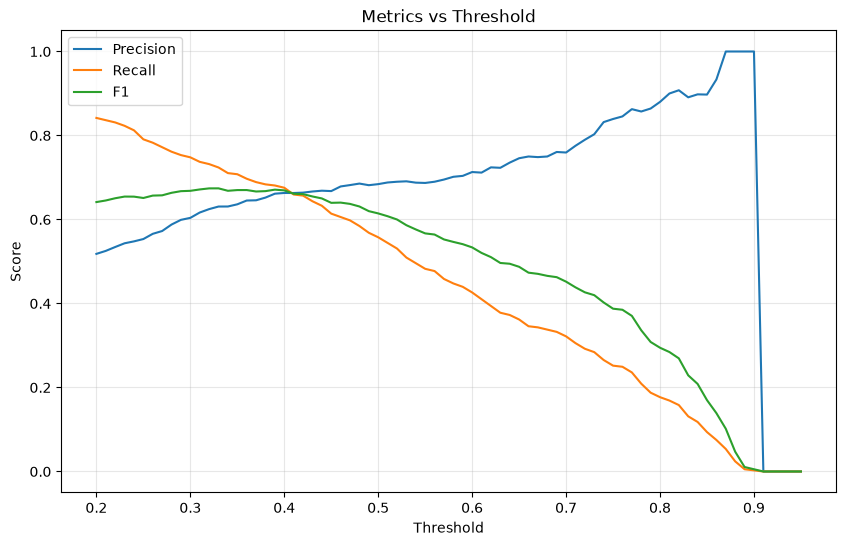

In [83]:
plt.figure(figsize = (10, 6))
plt.plot(threshold_df["threshold"], threshold_df["precision"], label = "Precision")
plt.plot(threshold_df["threshold"], threshold_df["recall"], label = "Recall")
plt.plot(threshold_df["threshold"], threshold_df["f1"], label = "F1")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Metrics vs Threshold")
plt.legend()
plt.grid(True, alpha = 0.3)
plt.show()

In [84]:
candidates = threshold_df[threshold_df["precision"] >= 0.50]
best_recall_row = candidates.loc[candidates["recall"].idxmax()]

In [85]:
threshold = best_recall_row["threshold"]
y_pred_opt = (y_proba_cal > threshold).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred_opt))
print(confusion_matrix(y_test, y_pred_opt))
print(classification_report(y_test, y_pred_opt))

Accuracy: 0.7508871540099361
[[744 292]
 [ 59 314]]
              precision    recall  f1-score   support

           0       0.93      0.72      0.81      1036
           1       0.52      0.84      0.64       373

    accuracy                           0.75      1409
   macro avg       0.72      0.78      0.73      1409
weighted avg       0.82      0.75      0.76      1409



#### SHAP values

In [86]:
explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(X_test)

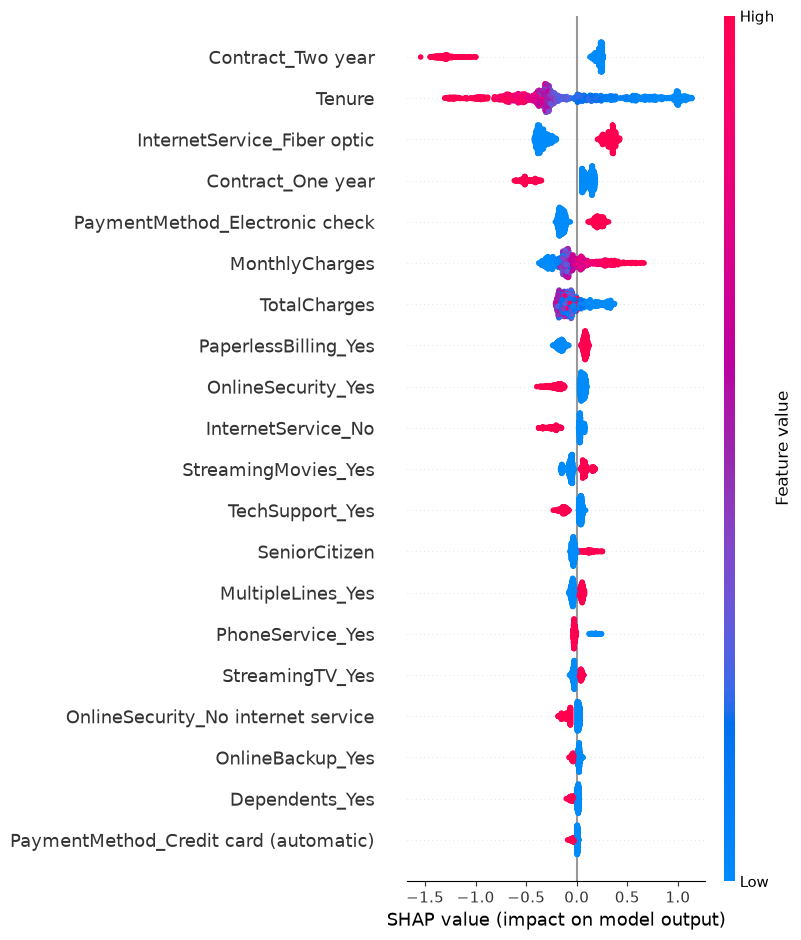

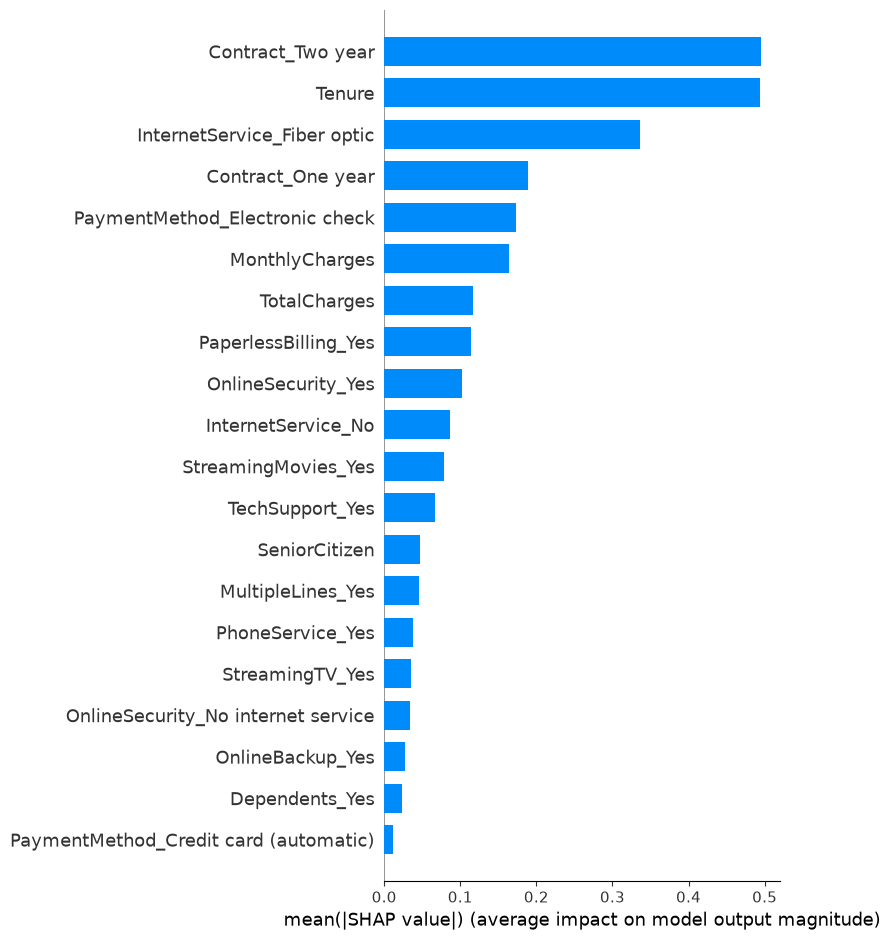

In [87]:
shap.summary_plot(shap_values, X_test)
shap.summary_plot(shap_values, X_test, plot_type="bar")

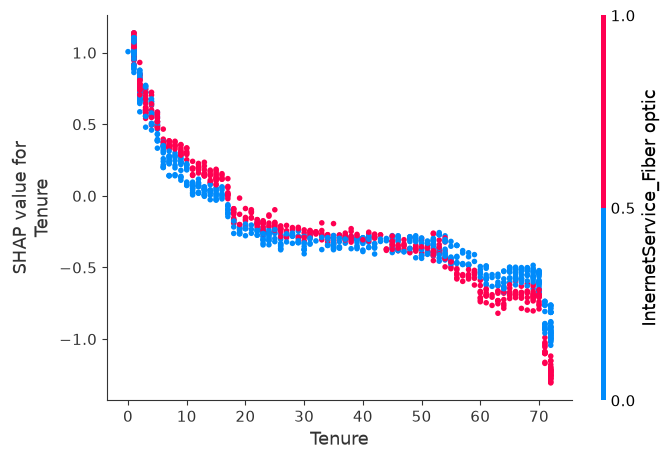

In [88]:
shap.initjs()
shap.force_plot(
    explainer.expected_value,
    shap_values[0],
    X_test.iloc[0]
)

shap.dependence_plot("Tenure", shap_values, X_test)

Customers are significantly more likely to churn during their first months. After this initial period, churn risk decreases sharply and stabilizes, indicating that customer retention strategies should focus on early lifecycle stages.

Add. : no strong interaction, so churn seems to be a tenure problem (duration) much more than a price one.

### Cost-benefit analysis

This section previously implemented a threshold analysis expressed in confusion-matrix quadrants relabelled as "TP caught / FP wasted", without any monetary anchor. It has been superseded by the value-based threshold selection implemented in src/business_value.py, whose outputs (reports/sensitivity.csv, reports/horizon_sensitivity.csv) are the authoritative artefacts. See the report.